## Definitions

In [1]:
!pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adadelta, Adam, SGD
from keras.layers import Input, Conv2D, Dense, MaxPooling2D, Dropout, Flatten, AveragePooling2D, Conv2DTranspose, UpSampling2D, BatchNormalization
from keras.models import Sequential
from keras.losses import categorical_crossentropy

from keras.datasets import mnist

I0000 00:00:1782116756.801027    9680 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1782116756.853245    9680 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1782116760.906582    9680 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Load and format data

Number of classes: 10
Example of handwritten digit with correlated noise: 



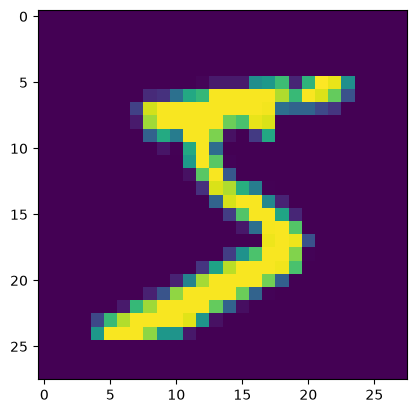

Class: 5

Shape of x_train: (60000, 28, 28, 1)
Shape of y_train: (60000, 10)


In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

num_cls = len(np.unique(y_train))
print('Number of classes: ' + str(num_cls))

print('Example of handwritten digit with correlated noise: \n')

k = 0
plt.imshow(np.squeeze(x_train[k,:,:]))
plt.show()
print('Class: '+str(y_train[k])+'\n')

# RESHAPE and standarize
x_train = np.expand_dims(x_train/255,axis=3)

# convert class vectors to binary class matrices
y_train = to_categorical(y_train, num_cls)

print('Shape of x_train: '+str(x_train.shape))
print('Shape of y_train: '+str(y_train.shape))

## Training

In [6]:
model_name='CNN_test1' # To compare models, you can give them different names

pweight='./weights/weights_' + model_name  + '.keras'

if not os.path.exists('./weights'):
  os.mkdir('./weights')


## EXPLORE VALUES AND FIND A GOOD SET
b_size = 4 # batch size
val_split = 0.5 # percentage of samples used for validation (e.g. 0.5)
ep = 3 # number of epochs

In [5]:
input_shape = x_train.shape[1:4] #(28,28,1)
model = Sequential()

## EXPLORE LAYERS, # CHANNELS... Conv2D, Dense, MaxPooling2D, Dropout, Flatten, AveragePooling2D, Conv2DTranspose, UpSampling2D
## SEE KERAS MANUAL https://keras.io/layers/about-keras-layers/
model.add(Conv2D(16, kernel_size=(3, 3), padding='same', activation='relu', input_shape=input_shape)) # explore num channels and adding more layers
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

##### 

model.add(Flatten()) # transforms matrix feature map to vector for dense layer (fully connected)

model.add(Dense(num_cls, activation='softmax')) # This is a necessary output layer, however, you can add more dense layers before with different activation functions


model.compile(loss=categorical_crossentropy,
              optimizer=SGD(learning_rate=0.01, momentum=0.9), # explore other optimizers: Adam, SGD, Adadelta
              metrics=['accuracy'])

model.summary()

checkpointer = ModelCheckpoint(filepath=pweight, verbose=1, save_best_only=True)
callbacks_list = [checkpointer] # explore adding other callbacks such as ReduceLROnPlateau, EarlyStopping

history=model.fit(x_train, y_train,
                        epochs=ep,
                        batch_size=b_size,
                        verbose=1,
                        shuffle=True,
                        validation_split = val_split,
                        callbacks=callbacks_list)

print('CNN weights saved in ' + pweight)

# Plot loss vs epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.show()

# Plot accuracy vs epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

/home/mario/ebis/04_neuronal/venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1782118099.636056    9680 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1782118099.669985    9680 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14, 14, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        31,370 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,594 (123.41 KB)

 Trainable params: 31,562 (123.29 KB)

 Non-trainable params: 32 (128.00 B)

Epoch 1/20
7498/7500 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8773 - loss: 0.4451
Epoch 1: val_loss improved from None to 0.17175, saving model to ./weights/weights_CNN_test1.keras

Epoch 1: finished saving model to ./weights/weights_CNN_test1.keras
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 105s 14ms/step - accuracy: 0.9172 - loss: 0.2905 - val_accuracy: 0.9515 - val_loss: 0.1718
Epoch 2/20
7499/7500 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9500 - loss: 0.1773
Epoch 2: val_loss did not improve from 0.17175
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 96s 13ms/step - accuracy: 0.9487 - loss: 0.1803 - val_accuracy: 0.9269 - val_loss: 0.2612
Epoch 3/20
5164/7500 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.9550 - loss: 0.1665

KeyboardInterrupt: 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2, 2, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        51,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 150,822 (589.15 KB)

 Trainable params: 150,142 (586.49 KB)

 Non-trainable params: 680 (2.66 KB)

Epoch 1/3
7498/7500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8374 - loss: 0.5359
Epoch 1: val_loss improved from None to 0.09989, saving model to ./weights/weights_CNN_test1.keras

Epoch 1: finished saving model to ./weights/weights_CNN_test1.keras
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 183s 24ms/step - accuracy: 0.8967 - loss: 0.3569 - val_accuracy: 0.9752 - val_loss: 0.0999
Epoch 2/3
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9433 - loss: 0.2024
Epoch 2: val_loss improved from 0.09989 to 0.06419, saving model to ./weights/weights_CNN_test1.keras

Epoch 2: finished saving model to ./weights/weights_CNN_test1.keras
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 180s 24ms/step - accuracy: 0.9454 - loss: 0.2015 - val_accuracy: 0.9818 - val_loss: 0.0642
Epoch 3/3
7499/7500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9497 - loss: 0.1781
Epoch 3: val_loss did not improve from 0.06419
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 180s 24ms/step - accuracy: 0.9537 - loss: 0.1645 - val_accuracy: 0.9818 - v

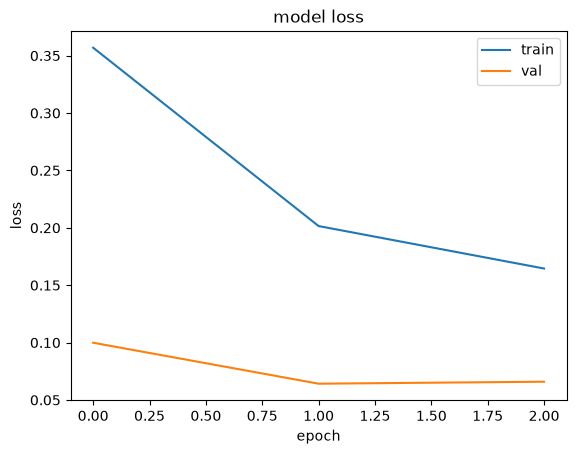

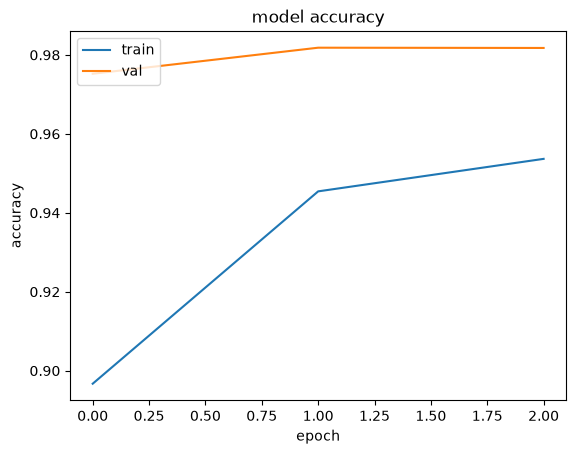

In [7]:
input_shape = x_train.shape[1:4] #(28,28,1)
model = Sequential()

## EXPLORE LAYERS, # CHANNELS... Conv2D, Dense, MaxPooling2D, Dropout, Flatten, AveragePooling2D, Conv2DTranspose, UpSampling2D
## SEE KERAS MANUAL https://keras.io/layers/about-keras-layers/
model.add(Conv2D(16, kernel_size=(3, 3), padding='same', activation='relu', input_shape=input_shape)) # explore num channels and adding more layers
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

model.add(Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(padding='same'))
model.add(BatchNormalization())

model.add(Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(padding='same'))
model.add(BatchNormalization())

model.add(Flatten()) # transforms matrix feature map to vector for dense layer (fully connected)

model.add(Dense(100, activation='relu'))
model.add(BatchNormalization())
model.add(Dense(num_cls, activation='softmax')) # This is a necessary output layer, however, you can add more dense layers before with different activation functions

model.compile(loss=categorical_crossentropy,
              optimizer=SGD(learning_rate=0.01, momentum=0.9), # explore other optimizers: Adam, SGD, Adadelta
              metrics=['accuracy'])

model.summary()

checkpointer = ModelCheckpoint(filepath=pweight, verbose=1, save_best_only=True)
callbacks_list = [checkpointer] # explore adding other callbacks such as ReduceLROnPlateau, EarlyStopping

history=model.fit(x_train, y_train,
                        epochs=ep,
                        batch_size=b_size,
                        verbose=1,
                        shuffle=True,
                        validation_split = val_split,
                        callbacks=callbacks_list)

print('CNN weights saved in ' + pweight)

# Plot loss vs epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.show()

# Plot accuracy vs epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

## Make predictions in test set

In [8]:
from keras.models import load_model

num_cls = len(np.unique(y_test))
print('Number of classes: ' + str(num_cls))

# RESHAPE and standarize
x_test = np.expand_dims(x_test/255,axis=3)

print('Shape of x_test: '+str(x_test.shape)+'\n')

## Define model parameters
model_name='CNN' # To compare models, you can give them different names
pweight='./weights/weights_' + model_name  + '.keras'

model = load_model(pweight)
y_pred_aux = model.predict(x_test)
y_pred=np.argmax(y_pred_aux,axis=1)

Acc_pred = sum(y_pred == y_test)/len(y_test)

print('Accuracy in test set is: '+str(Acc_pred))


Number of classes: 10
Shape of x_test: (10000, 28, 28, 1)



ValueError: File not found: filepath=./weights/weights_CNN.keras. Please ensure the file is an accessible `.keras` zip file.